# Comparing decomposition methods for unitary matrices and their implementation in integrated photonics
- **Authors:** Andrea Barletta, Yanlong Wang
- **Abstract:** In our project we will compare the fidelity of three different architectures for universal multiport interferometers, used to perform any unitary or linear transformation. In particular we will focus on comparing the traditional Reck and Clements architectures with a Universal Generalized Mach–Zehnder Interferometer (UGMZI) architecture, inspired by the work of P. Dita, which allows for a fidelity restoration mechanism

## Imports and Helper functions

### Imports

In [78]:
import numpy as np
import matplotlib.pyplot as plt
from circuit.interferometer import interferometer as itf
from circuit.component import component as cmp
from circuit.component import component_type as cmp_type

### Utils

In [79]:
# Set seed globally for reproducibility
np.random.seed(42)

# Function to generate a random unitary matrix of size N x N
def random_unitary(N):
    X = np.zeros([N, N], dtype=np.complex128)
    for ii in range(N):
        for jj in range(N):
            X[ii, jj] = (np.random.normal() + 1j * np.random.normal()) / np.sqrt(2)

    q, r = np.linalg.qr(X)
    r = np.diag(np.divide(np.diag(r), abs(np.diag(r))))
    U = np.matmul(q, r)

    return U

# Function to get arctangent of the absolute ratio of two numbers
def my_atan(x1, x2):
    if x2 != 0:
        return np.arctan(abs(x1/x2))
    else:
        return np.pi/2

# Function to get the angle of the ratio of two complex numbers
def my_angle(x1, x2):
    if x2 != 0:
        return np.angle(x1/x2)
    else:
        return 0

## Building blocks

The building blocks of the photonic circuit are defined in the `component.py` file. The main components are:

### Beam splitters
We will use 2x2 beam splitters with tunable reflectivity and with a phase shifter at one of the inputs.\\
Its graphical representation and transfer function is the following:

<p align="center">
    <img src="images/beamsplitter.svg?1" width="80%" />
</p>

*Note* We could also use MZI instead of Beam splitters, as they are equivalent (up to a change of parameters), however beam splitters are more suitable as their parameters are easier to obtain from the math formulations

### Phase shiters
We will use tunable phase shifters acting on one mode at a time.\\
Its graphical representation and transfer function is the following:

<p align="center">
    <img src="images/phaseshifter.svg" width="80%" />
</p>

### Losses
We will model losses as described in [3], where we will introduce a component where the loss occurs.
Its graphical representation and transfer function is the following:

<p align="center">
    <img src="images/losselement.svg" width="80%" />
</p>

## Math preliminaries

### Givens rotation

A Givens rotation is a rotation in the plane spanned by two coordinates axes. The main use of Givens rotations is to transform vectors or matrices into a special form with zeros in certain coefficients.<br>
A Givens rotation acting on row $r$ and column $c$ acting on a $N\times N$ matrix is defined as follows
$$

T_{c,r}(\theta,\varphi)=\left[
    \begin{array}{ccccc}
    I_{c-1} & 0 & \dots & 0 & 0\\
    0 & e^{i\varphi}\cos(\theta) & \dots & -\sin(\theta) & 0\\
    \vdots & \vdots & I_{r-c-1} & \vdots & \vdots \\
    0 & e^{i\varphi}\sin(\theta) & \dots & \cos(\theta) & 0\\
    0 & 0 & \dots & 0 & I_{N-r}\\
    \end{array}
\right]
$$

It's immediate to notice how a Givens rotation can be imlemented with a single beam splitter, acting on mode $c$ and $r$m with the same exact parameters as the rotation.

In particular, we will use Given rotations to nullify a specific element of a matrix

### The unitary group $U(N)$


The main concepts required for understanding how the decompositions work are the following:
1) **Unitary property**: Given a matrix $A\in U(N)$, and denoting with $A^\dagger$ its adjoint (conjugate transpose), we have the following $$AA^\dagger=A^\dagger A=I_N$$
2) **Group properies**: Given two unitary matrices, their product is a unitary matrix, that is
$$A,B\in U(N) \implies AB,BA\in U(N)$$
3) **Multiplication with diagonal matrix**: Multiplying a matrix by a diagonal matrix on the left, we obtain a matrix where each row $k$ is multilied by the diagonal element in position $d_{kk}$. Multiplying on the right yields the same result, except for columns.<br><br>
4) **Transitive action**: $U(N)$, which is $\simeq Aut\left(\mathcal{H}(\mathbb{C^N})\right)$, acts transitively on the unit sphere $\mathbb{S}_{2n-1}\subseteq \mathcal{H}(\mathbb{C^N})$<br><br>

Properties $3)$ and $4)$ will be used extensively in the UGMZI decomposition scheme

## Reck's Method

### Idea

The idea of Reck's method is to iteratively apply Givens rotations to cancel all the elements except the ones on the diagonal.<br>
That is, we will obtain the following:
$$
 U(N)R_NR_{N-1}\dots R_2 = diag\left(e^{i\varphi_1},e^{i\varphi_2},\dots,e^{i\varphi_N}\right)
$$

The matrix $R_j$ acts on $U(N)$ by eliminating all elements in row and column $j$, with the exception of the element in position $(j,j)$<br>
For example,
$$
U(4)R_4 = \left[
    \begin{array}{cccc}
        * & * & * & 0\\
        * & * & * & 0\\
        * & * & * & 0\\
        0 & 0 & 0 & e^{i\varphi_4}
    \end{array}
\right]
$$

We can further decompose the matrices $R_j$ as a product of (adjoint) Givens rotations as follows:
$$
    R_j = \prod_{k=j-1}^{1} T_{j,k}^\dagger(\theta_k,\varphi_k)
$$
where
$$
T^\dagger_{j,k}(\theta_k, \phi_k) =\left[
    \begin{array}{ccccc}
    I_{j-1} & 0 & \dots & 0\\
    0 & e^{-i\varphi}\cos(\theta) & e^{-i\varphi}\sin(\theta) & \vdots\\
    \vdots & -\sin(\theta) & \cos(\theta) & \vdots\\
    0  & \dots & \dots & I_{N-k}\\
    \end{array}
\right]
$$

From the unitarity of the operators $R_j$, we get the desired decompositon
$$
    U(N) = diag\left(e^{i\varphi_1},e^{i\varphi_2},\dots,e^{i\varphi_N}\right)\prod_{j=N}^{2}\prod_{k=1}^{j-1}T_{j,k}(\theta_{j,k},\varphi_{j,k})
$$

The implementation in photonics is immediate: The matrices $T_{j,k}(\theta_{j,k},\varphi_{j,k})$ are beam splitter, the diagonal matrix is an array of phase shifters<br><br>
Moreover, we see how the total number of beam splitter is $\frac{N(N-1)}{2}$

### Determining the parameters

Since for row $k$ we want columns $j\neq k$ to be 0, we can compute the $\theta$ and $\varphi$ parameters by imposing the following equality, obtained from the matrix $T_{j,k}^\dagger(\theta_k,\varphi_k)$ acting on $U$ on the right:
$$
x_j \cos(\theta) - x_k e^{-i\phi} \sin(\theta) = 0
$$

We can therefore derive the following values for $\theta$ and $\varphi$:
$$
\begin{aligned}
    \theta &= \arctan \left( \left| \frac{x_n}{x_m} \right| \right) \\\\
    \phi   &= -\arg \left( -\frac{x_n}{x_m} \right)
\end{aligned}

### Topology

From the math formulation and the observations about the implementation of each transformation as a photonic component, we obtain the following topology for the Reck's decomposition

<p align="center">
    <img src="images/reck.svg" width="60%"/>
</p>

### Python implementation

In [80]:
def decompose_reck(U,verbose=False):
    I = itf()
    N = int(np.sqrt(U.size))
    # Loop over each layer in the Reck triangular decomposition
    for i in range(N-1):
        # Each layer acts on a decreasing number of modes
        for j in range(N-1-i):
            modes = [N - j - 1, N - j]
            # Calculate the theta and phi for the inverse T matrix
            theta = my_atan(U[i, N - 1 - j], U[i, N - 2 - j])
            phi = -my_angle(-U[i, N - 1 - j], U[i, N - 2 - j])
            invT = np.eye(N, dtype=np.complex128)
            # Fill in the inverse T matrix based on the previous results
            invT[modes[0]-1, modes[0]-1] = np.exp(-1j * phi) * np.cos(theta)
            invT[modes[0]-1, modes[1]-1] = np.exp(-1j * phi) * np.sin(theta)
            invT[modes[1]-1, modes[0]-1] = -np.sin(theta)
            invT[modes[1]-1, modes[1]-1] = np.cos(theta)
            # Apply the inverse T matrix to the unitary matrix from right (affect 2 columns of U)
            U = np.matmul(U, invT)
            # Print to verify matrix after applying the inverse T matrix each step
            if verbose: 
                print(f"U {np.round(U,3)}\n")
            I.comp_list.append(cmp(cmp_type.BEAM_SPLITTER, (modes), (theta, phi)))
            for mode in modes:
                I.comp_list.append(cmp(cmp_type.LOSS_ELEMENT, (mode,), ()))
            # Add a loss term
    phases = np.diag(U)
    I.output_phases = [np.angle(i) for i in phases]
    return I

Once we have our Reck decomposition function, we can use the interferometer `.calculate_transformation()` method to compute the reconstructed unitary, and also use the `.draw()` function to see the layout

For example:

U [[ 0.334-0.093j  0.112+0.556j -0.738-0.115j -0.   -0.j   ]
 [-0.316+0.365j  0.308-0.082j -0.18 -0.148j -0.579+0.526j]
 [-0.681+0.211j  0.041-0.139j -0.416-0.107j  0.471-0.255j]
 [-0.366+0.075j -0.417+0.618j  0.161+0.421j  0.063+0.313j]]

U [[ 0.334-0.093j  0.927+0.145j -0.   -0.j    -0.   -0.j   ]
 [-0.316+0.365j  0.162-0.074j -0.085-0.342j -0.579+0.526j]
 [-0.681+0.211j  0.261+0.033j -0.343-0.134j  0.471-0.255j]
 [-0.366+0.075j  0.134+0.031j  0.444+0.737j  0.063+0.313j]]

U [[-0.988-0.154j -0.   +0.j    -0.   -0.j    -0.   -0.j   ]
 [-0.   +0.j     0.467-0.215j -0.085-0.342j -0.579+0.526j]
 [ 0.   -0.j     0.754+0.095j -0.343-0.134j  0.471-0.255j]
 [ 0.   -0.j     0.388+0.089j  0.444+0.737j  0.063+0.313j]]

U [[-0.988-0.154j -0.   +0.j     0.   -0.j    -0.   -0.j   ]
 [-0.   +0.j     0.467-0.215j  0.635-0.577j  0.   -0.j   ]
 [ 0.   -0.j     0.754+0.095j -0.448+0.082j  0.153-0.438j]
 [ 0.   -0.j     0.388+0.089j -0.238+0.019j -0.374+0.803j]]

U [[-0.988-0.154j  0.   -0.j     0.   -0

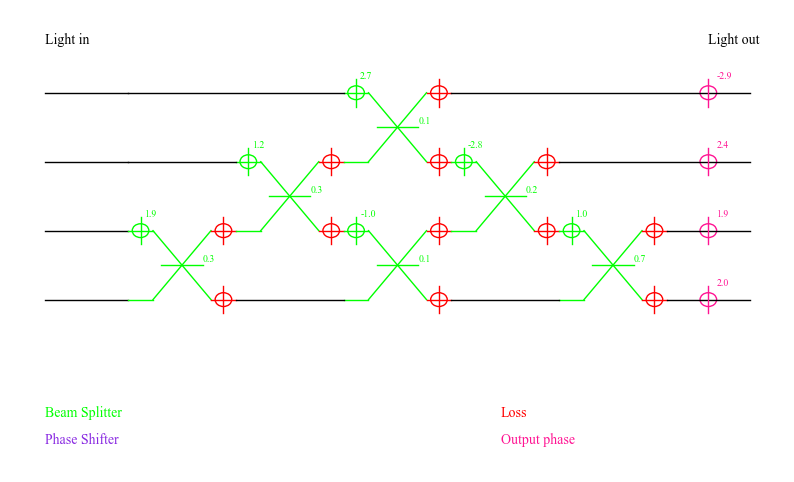

Frobenius norm: 6.967630807752464e-16


In [81]:
U = random_unitary(4)
I = decompose_reck(U,verbose=True)
I.draw()

Uexp = I.calculate_transformation()

print("Frobenius norm:", np.linalg.norm(Uexp - U))

As indicated by the Frobenius norm, we have a good approximation of the orginal matrix

## Clements' Method

### Idea

Clements' method is an optimized arrangement beyond Reck's.<br>
This method uses both $T$ from left effecting the rows, and $T^\dagger$ matrices from the right effecting the columns, yielding a different elimination order.<br>
In particular, we will obtain a decomposition in the form:
$$
\left(\prod_{(i,j)\in C_1}T_{i,j}(\theta_{i,j},\varphi_{i,j})\right) U(N) \left(\prod_{(k,l)\in C_2}T_{k,l}^\dagger(\theta_{k,l},\varphi_{k,l})\right) = A
$$
where $A$ is an upper triangular matrix, and $C_1$ $C_2$ are a suitable set of indices. <br>
Notice how we don't obtain a diagonal matrix at the end of the decomposition. However, using the property that, up to a parameter change, $T^\dagger_{m,n}(\theta,\varphi)A=A' T_{m,n}(\theta',\varphi')$, we obtain the following formulation
$$
U(N) = diag\left(e^{i\varphi_1},e^{i\varphi_2},\dots,e^{i\varphi_N}\right)\left(\prod_{(i,j)\in C_1}^{\text{reverse}}T_{i,j}(\theta_{i,j},\varphi_{i,j})\right)\left(\prod_{(k,l)\in C_2}^{\text{reverse}}T_{k,l}(\theta_{k,l},\varphi_{k,l})\right)
$$

For clarity, we will proceed with a guided example on a matrix $U\in U(4)$
$$
U=
\left[
    \begin{array}{cccc}
    * & * & * & * \\
    * & * & * & * \\
    * & * & * & * \\
    * & * & * & *
    \end{array}
\right]
\rightarrow
UT_{2,1}^\dagger = 
\left[
    \begin{array}{cccc}
    * & * & * & * \\
    * & * & * & * \\
    * & * & * & * \\
    0 & * & * & *
    \end{array}
\right]
\rightarrow
T_{3,2}UT_{2,1}^\dagger = 
\left[
    \begin{array}{cccc}
    * & * & * & * \\
    * & * & * & * \\
    0 & * & * & * \\
    0 & * & * & *
    \end{array}
\right]
\rightarrow
T_{4,3}T_{3,2}UT_{2,1}^\dagger = 
\left[
    \begin{array}{cccc}
    * & * & * & * \\
    * & * & * & * \\
    0 & * & * & * \\
    0 & 0 & * & *
    \end{array}
\right]
$$
$$
\rightarrow
T_{4,3}T_{3,2}UT_{2,1}^\dagger T_{4,3}^\dagger = 
\left[
    \begin{array}{cccc}
    * & * & * & * \\
    * & * & * & * \\
    0 & * & * & * \\
    0 & 0 & 0 & *
    \end{array}
\right]
\rightarrow
T_{4,3}T_{3,2}UT_{2,1}^\dagger T_{4,3}^\dagger T_{3,2}^\dagger = 
\left[
    \begin{array}{cccc}
    * & * & * & * \\
    * & * & * & * \\
    0 & 0 & * & * \\
    0 & 0 & 0 & *
    \end{array}
\right]
\rightarrow
T_{4,3}T_{3,2}UT_{2,1}^\dagger T_{4,3}^\dagger T_{3,2}^\dagger T_{2,1}^\dagger= 
\left[
    \begin{array}{cccc}
    * & * & * & * \\
    0 & * & * & * \\
    0 & 0 & * & * \\
    0 & 0 & 0 & *
    \end{array}
\right]
$$

As we can see, we will proceed in a zig-zag manner, starting from the bottom left-most corner.<br><br>
The total number of beam splitters is $\frac{N(N-1)}{2}$, which is same as Reck's method but as we will see it yields a more equal distribution of the beam splitters (and as a consequence of the losses)

### Determining the parameters

The $\theta$ and $\varphi$ parameters for $T$ and $T^\dagger$ matrices are determined by elimination conditions on the elements of the original matrix:

- $T_{j,k}(\theta,\varphi)$ matrices applied on the left give the following equality:
    $$
        x_j e^{i\varphi} \sin(\theta) + x_k \cos(\theta) = 0
    $$

    We can therefore derive the following values for $\theta$ and $\varphi$:

    $$
        \begin{aligned}
            \theta &= \arctan \left( \left| \frac{x_k}{x_j} \right| \right) \\\\
            \varphi   &= \arg \left( -\frac{x_k}{x_j} \right)
        \end{aligned}
    $$

- $T^\dagger_{j,k}(\theta,\varphi)$ matrices applied on right give the following equality:
    $$
        x_j e^{-i\phi} \cos(\theta) - x_k \sin(\theta) = 0
    $$

    We can therefore derive the following values for $\theta$ and $\varphi$:

    $$
    \begin{aligned}
        \theta &= \arctan \left( \left| \frac{x_j}{x_k} \right| \right) \\\\
        \varphi   &= \arg \left( \frac{x_j}{x_k} \right)
    \end{aligned}
    $$

### Topology

From the math formulation and the observations about the implementation of each transformation as a photonic component, we obtain the following topology for the Reck's decomposition

<p align="center">
    <img src="images/clements.svg" width="60%"/>
</p>

### Python implementation

In [82]:
def decompose_clements(U, verbose=False):
    I = itf()
    N = int(np.sqrt(U.size))
    left_T = []
    for i in range(N-1):
        # Determine if using T or T-inverse based on the layer index
        if np.mod(i, 2) == 0:
            for j in range(i+1):
                # The sequence is an offdiagonal shape, from right column elimination to left column elimination
                modes = [i - j + 1, i + 2 - j]
                # Calculate theta and phi for the T inverse matrix
                theta = my_atan(U[N-1-j, i-j], U[N-1-j, i-j+1])
                phi = my_angle(U[N-1-j, i-j], U[N-1-j, i-j+1])
                invT = np.eye(N, dtype=np.complex128)
                invT[modes[0]-1, modes[0]-1] = np.exp(-1j * phi) * np.cos(theta)
                invT[modes[0]-1, modes[1]-1] = np.exp(-1j * phi) * np.sin(theta)
                invT[modes[1]-1, modes[0]-1] = -np.sin(theta)
                invT[modes[1]-1, modes[1]-1] = np.cos(theta)
                # Apply the inverse T matrix to the unitary matrix from right (affect 2 columns of U)
                U = np.matmul(U, invT)
                if verbose: 
                    print(f"U {np.round(U,3)}\n")
                I.comp_list.append(cmp(cmp_type.BEAM_SPLITTER, (modes), (theta, phi)))
                for mode in modes:
                    I.comp_list.append(cmp(cmp_type.LOSS_ELEMENT, (mode,), ()))
        else:
            for j in range(i+1):
                # The sequence is an offdiagonal shape, from top row elimination to bottom row elimination
                modes = [N+j-i-1, N+j-i]
                # Calculate theta and phi for the T matrix
                theta = my_atan(U[N+j-i-1, j], U[N+j-i-2, j])
                phi = my_angle(-U[N+j-i-1, j], U[N+j-i-2, j])
                T = np.eye(N, dtype=np.complex128)
                T[modes[0]-1, modes[0]-1] = np.exp(1j * phi) * np.cos(theta)
                T[modes[0]-1, modes[1]-1] = -np.sin(theta)
                T[modes[1]-1, modes[0]-1] = np.exp(1j * phi) * np.sin(theta)
                T[modes[1]-1, modes[1]-1] = np.cos(theta)
                # Apply the T matrix to the unitary matrix from left (affect 2 rows of U)
                U = np.matmul(T, U)
                if verbose: 
                    print(f"U {np.round(U,3)}\n")
                left_T.append(cmp(cmp_type.BEAM_SPLITTER, (modes), (theta, phi)))

    for comp in np.flip(left_T, 0):
        modes = [int(comp.modes[0]), int(comp.modes[1])]
        invT = np.eye(N, dtype=np.complex128)
        invT[modes[0]-1, modes[0]-1] = np.exp(-1j * comp.params[1]) * np.cos(comp.params[0])
        invT[modes[0]-1, modes[1]-1] = np.exp(-1j * comp.params[1]) * np.sin(comp.params[0])
        invT[modes[1]-1, modes[0]-1] = -np.sin(comp.params[0])
        invT[modes[1]-1, modes[1]-1] = np.cos(comp.params[0])
        U = np.matmul(invT, U)
        theta = my_atan(U[modes[1]-1, modes[0]-1], U[modes[1]-1, modes[1]-1])
        phi = my_angle(U[modes[1]-1, modes[0]-1], U[modes[1]-1, modes[1]-1])
        invT[modes[0]-1, modes[0]-1] = np.exp(-1j * phi) * np.cos(theta)
        invT[modes[0]-1, modes[1]-1] = np.exp(-1j * phi) * np.sin(theta)
        invT[modes[1]-1, modes[0]-1] = -np.sin(theta)
        invT[modes[1]-1, modes[1]-1] = np.cos(theta)
        U = np.matmul(U, invT)
        I.comp_list.append(cmp(cmp_type.BEAM_SPLITTER, (modes), (theta, phi)))
        for mode in modes:
                I.comp_list.append(cmp(cmp_type.LOSS_ELEMENT, (mode,), ()))
    phases = np.diag(U)
    I.output_phases = [np.angle(i) for i in phases]
    return I

Once we have our Clements decomposition function, we can use the interferometer `.calculate_transformation()` method to compute the reconstructed unitary, and also use the `.draw()` function to see the layout

For example:

U [[-0.473+0.537j  0.216-0.319j  0.093-0.436j -0.337-0.166j]
 [-0.071-0.13j  -0.216-0.322j -0.499-0.176j  0.443-0.592j]
 [-0.578+0.364j -0.244+0.206j -0.191+0.3j    0.423+0.355j]
 [ 0.   +0.j     0.322+0.704j -0.493-0.389j -0.079-0.028j]]

U [[-0.473+0.537j  0.216-0.319j  0.093-0.436j -0.337-0.166j]
 [ 0.591-0.372j  0.304-0.251j  0.217-0.402j -0.282-0.261j]
 [ 0.   +0.j     0.25 -0.186j  0.102-0.434j  0.693+0.473j]
 [ 0.   +0.j     0.322+0.704j -0.493-0.389j -0.079-0.028j]]

U [[-0.473+0.537j  0.216-0.319j  0.093-0.436j -0.337-0.166j]
 [ 0.591-0.372j  0.304-0.251j  0.217-0.402j -0.282-0.261j]
 [-0.   -0.j    -0.348-0.758j  0.307+0.29j   0.3  -0.19j ]
 [ 0.   +0.j    -0.   -0.j    -0.557-0.322j  0.534-0.548j]]

U [[-0.473+0.537j  0.216-0.319j  0.523+0.258j -0.   -0.j   ]
 [ 0.591-0.372j  0.304-0.251j  0.438+0.405j  0.   +0.j   ]
 [-0.   -0.j    -0.348-0.758j -0.466+0.295j -0.   +0.j   ]
 [ 0.   +0.j    -0.   -0.j    -0.   +0.j     0.698-0.716j]]

U [[-0.473+0.537j -0.627-0.309j  0.   -0

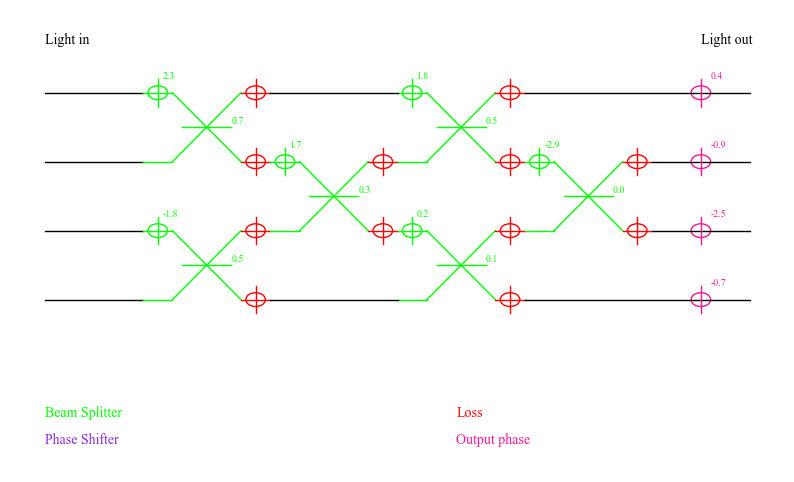

Frobenius norm: 6.072424243885148e-16


In [83]:
U = random_unitary(4)
I = decompose_clements(U,verbose=True)
I.draw()
Uexp = I.calculate_transformation()

print("Frobenius norm:", np.linalg.norm(Uexp - U))

As indicated by the Frobenius norm, we have a good approximation of the orginal matrix

## UGMZI Decomposition

In this decomposition, inspired by P.Dita, we will decompose a unitary matrix U in the form
$$
 U = d_n\mathcal{O}_nd_{n-1}^1\mathcal{O}_{n-1}^1\dots d_{2}^{n-2}\mathcal{O}_2^{n-2}d_1^{n-1}
$$

Where the $d_k$ matrices are diagonal matrices with the last $k$ elements equal to $e^{i\varphi_l}$, and the $\mathcal{O}_{n-k}^k$ matrices are obtained by multiplying Givens rotations as follows

$$
\mathcal{O}_{n-k} = J_{n-k-1,n-k}J_{n-k-2,n-k-1}\dots J_{1,2}
$$

and extendeted to dimension $n$ by placing them in the bottom-right corner of an identity matrix, that is

$$
\mathcal{O}_{n-k}^k = \begin{bmatrix} I_k & 0 \\ 0 & O_{n-k}\end{bmatrix}
$$

The implementation with the photonic circuit is immediate, using a column of phase shifter for the $d$ matrices, and a cascade of beam splitters for the $O$ matrices

In [84]:
def decompose_ugmzi(U):
    N = int(np.sqrt(U.size))
    I = itf()
    # Notice that we will decompose from n->1, so we will have to insert the elements in the circuit in reverse order
    # Extract the output phases (we will add these at the end)
    phases = np.angle(U[:, 0])
    Dd = np.diag(np.exp(-1j*phases))
    U = Dd @ U
    I.output_phases = phases
    for n in range(N, 1, -1):
        # Compute the appropriate Givens rotations to have the matrix in the form [1 0; 0 U']
        for i in range(n-1, 0, -1):
            u = U[:, 0]
            theta = my_atan(u[i], u[i-1])
            O = np.eye(n, dtype=np.complex128)
            # theta = my_atan(u[j], u[j-1])
            O[i-1][i-1] = np.cos(theta)
            O[i-1][i] = np.sin(theta)
            O[i][i-1] = -np.sin(theta)
            O[i][i] = np.cos(theta)
            U = O @ U
            I.comp_list.insert(0,cmp(cmp_type.BEAM_SPLITTER, (N-n+i, N-n+i+1), (theta, 0)))
            I.comp_list.insert(1, cmp(cmp_type.LOSS_ELEMENT, (N-n+i,), ()))
            I.comp_list.insert(1, cmp(cmp_type.LOSS_ELEMENT, (N-n+i+1,), ()))

        # Resize the matrix U
        U = U[1:, 1:]
        
        # Extract the phases to make the first column real and positive
        phases = np.angle(U[:, 0])
        Dd = np.diag(np.exp(-1j*phases))
        U = Dd @ U
        phases = phases[::-1]
        for i in range(len(phases)):
            I.comp_list.insert(0,cmp(cmp_type.PHASE_SHIFTER, (N-i,), (phases[i],)))
            
        I.comp_list.insert(0, cmp(cmp_type.BARRIER, (-1,), ()))
        

    #Insert the loss related to the first block
    I.comp_list.insert(1, cmp(cmp_type.LOSS_ELEMENT, (N,), ()))
    return I

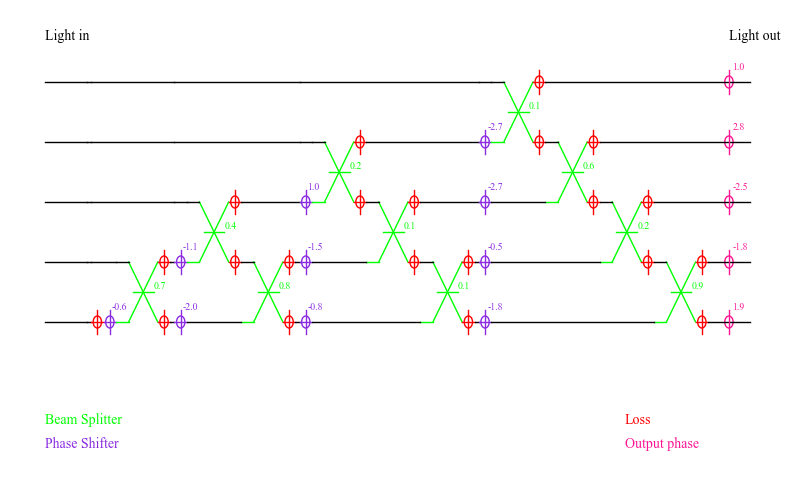

Frobenius norm: 8.725659353597275e-16


In [85]:
U = random_unitary(5)
I = decompose_ugmzi(U)
I.draw()

Uexp = I.calculate_transformation()

print("Frobenius norm:", np.linalg.norm(Uexp - U))

In [86]:
def fidelity_restorer(N,LN_dB):
    # Number of phase shifter (exluding final ones) on mode k = k-1
    # Number of BS on mode k = 2k-1, except for the last one which has N-1
    kn = 10**(-LN_dB/10)
    attenuation = np.array([], dtype=np.float64)
    for i in range(1,N):
        total_loss = kn**(2*i-1)
        print("Total loss for mode", i, ":", 1/total_loss)
        attenuation = np.append(attenuation, total_loss)

    attenuation = np.append(attenuation, 1/kn**(N-1))
    return attenuation

In [87]:
LN_dB = -1.5
U = random_unitary(3)
Uexp = decompose_ugmzi(U).calculate_transformation(LN_dB=LN_dB)
Thing = U.conj().T @ Uexp
print("Thing:", Thing)
# x = random_unitary(5)[0,:]
# y = U @ x
# yexp = Uexp @ x
# print("Output error:", np.linalg.norm(yexp - y)/np.linalg.norm(y))
# y_restored = Uexp @ np.diag(fidelity_restorer(5, LN_dB)) @ x
# print("Restored output error:", np.linalg.norm(y_restored - y)/np.linalg.norm(y))

Thing: [[1.40259424+8.32667268e-17j 0.03711413-1.60977158e-02j
  0.03749045-2.30258935e-02j]
 [0.03122765+1.35445399e-02j 1.41896947-5.55111512e-17j
  0.00692512-9.86742058e-04j]
 [0.02654121+1.63010842e-02j 0.00582677+8.30239973e-04j
  1.68520495+1.00613962e-16j]]


## Fidelity

### Definition

Implementation of an arbitrary unitary matrix with realistic, nonideal optical components will result in a discrepancy between the achieved and targeted matrix element values.<br>
To quantify this discrepancy, we rely on the fidelity parameter, defined as follows:

$$
F(U,U_{\text{exp}})=\left|\frac{\text{tr}(U^\dagger U_{\text{exp}})}{\text{tr}(\sqrt(U^\dagger U))\text{tr}(U_{\text{exp}}^\dagger U_{\text{exp}})}\right|^2
$$

where $U\in U(N)$ is the targeted unitary matrix and $U_{\text{exp}}$ is its experimental counterpart.<br>
Notice that, although the matrix $U$ is unitary, it's not guaranteed that $U_{\text{exp}}$ will be too.<br>

### Python implementation

In [88]:
def Fid(U, Uexp):
    return np.abs(np.trace(U @ Uexp.conj().T) / 
      np.sqrt(
          np.trace(U @ U.conj().T)*np.trace(Uexp @ Uexp.conj().T)
      ))**2

### Fidelity vs Parameters error

The first thing we want to explore is how the different methods behave when the parameters are not set exactly, which could be the result of errors in calibration.<br>
In particular, we will see how the decompositions behave with an increasing standard deviation from the ideal parameters.<br>
We will proceed with a Monte Carlo method, fixing the size of the matrices.

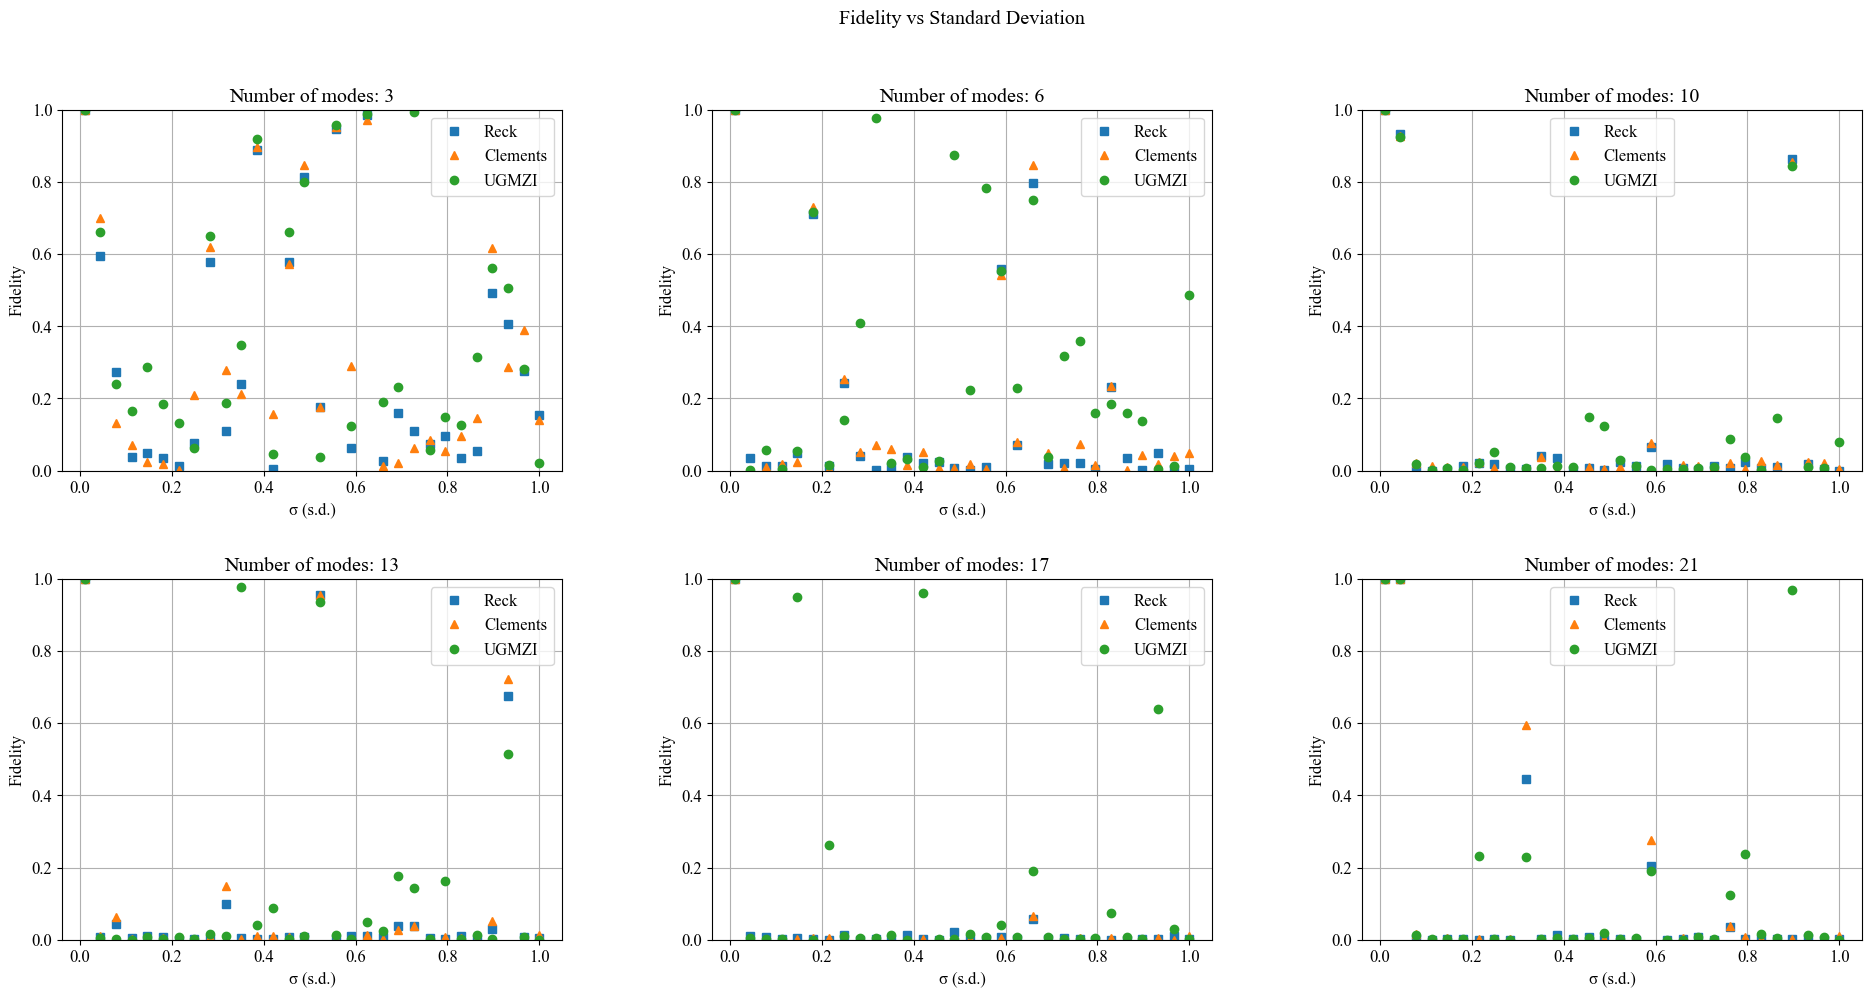

In [ ]:
NUM_MODE = np.linspace(3,21,6)
S_DEV = np.linspace(0.01, 1.0, 30)
COUNT = 10

# Matplotlib setup
plots = []
fig, plots = plt.subplots(2,3, figsize=(20, 10))
plt.subplots_adjust(left=0.05, right=0.95, bottom=0.05, wspace=0.3, hspace=0.3)
fig.suptitle('Fidelity vs Standard Deviation')
x = S_DEV

for i in range(NUM_MODE.size):
    ax = plots[i//3, i%3]
    ax.set_title(f'Number of modes: {int(NUM_MODE[i])}')
    ax.set_xlabel('σ (s.d.)')
    ax.set_ylabel('Fidelity')
    ax.grid()
    ax.set_ylim(0, 1)
    fidelity = np.zeros((len(S_DEV), 3))
    
    for sd in range(len(S_DEV)):
        total = np.zeros(3)
        for _ in range(COUNT):
            # Compute the circuits
            U = random_unitary(int(NUM_MODE[i]))
            circuit_reck = decompose_reck(U)
            circuit_clements = decompose_clements(U)
            circuit_ugmzi = decompose_ugmzi(U)
            
            # Compute the experimental transformations with parameter errors
            error = np.random.normal(0, sd)
            
            # Reck
            Uexp_reck = circuit_reck.calculate_transformation(params_error=error)
            total[0] += Fid(U, Uexp_reck)
            
            # Clements
            Uexp_clements = circuit_clements.calculate_transformation(params_error=error)
            total[1] += Fid(U, Uexp_clements)
            
            # UGMZI
            Uexp_ugmzi = circuit_ugmzi.calculate_transformation(params_error=error)
            total[2] += Fid(U, Uexp_ugmzi)

        fidelity[sd] = total / COUNT
    
    # Draw the plot
    ax.plot(x,fidelity[:,0],'s')
    ax.plot(x,fidelity[:,1],'^')
    ax.plot(x,fidelity[:,2],'o')

    ax.legend(['Reck', 'Clements', 'UGMZI'])


plt.show()

In [ ]:
# System Configurations and Parameters
NUM_MODE = 31
LN_dB=-0.5
COUNT = 30

# Buffers to store the data for drawings
fidelity = np.zeros((NUM_MODE, 1))

# Setup for Matplotlib
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.weight"] = "normal"
plt.rcParams["font.size"] = 12
plt.figure(dpi=300)
plt.grid()
x = range(3, NUM_MODE)

# Sweep Parameters [Reck]
for i in range(3, NUM_MODE):
    total = 0.0
    for _ in range(COUNT):
        U = random_unitary(i)
        circuit = decompose_reck(U)
        Uexp = circuit.calculate_transformation(LN_dB=LN_dB)
        total += Fid(U, Uexp)
    fidelity[i] = total / COUNT

# Annotate Setup
y_reck = fidelity[3:NUM_MODE].copy()
plt.plot(x, y_reck, 's', markersize=2)

# Sweep Parameters [Clements]
for i in range(3, NUM_MODE):
    total = 0.0
    for _ in range(COUNT):
        U = random_unitary(i)
        circuit = decompose_clements(U)
        Uexp = circuit.calculate_transformation(LN_dB=LN_dB)
        total += Fid(U, Uexp)
    fidelity[i] = total / COUNT

# Annotate Setup
y_clements = fidelity[3:NUM_MODE].copy()
plt.plot(x, y_clements, '^', markersize=2)

# Sweep Parameters [UGMZI]
for i in range(3, NUM_MODE):
    total = 0.0
    for _ in range(COUNT):
        U = random_unitary(i)
        circuit = decompose_ugmzi(U)
        Uexp = circuit.calculate_transformation(LN_dB=LN_dB)
        total += Fid(U, Uexp)
    fidelity[i] = total / COUNT

# Annotate Setup
y_ugmzi = fidelity[3:NUM_MODE].copy()
plt.plot(x, y_ugmzi, 'o', markersize=2)

# Decorate Figures
plt.xlabel('Number of modes', fontsize=14)
plt.ylabel('Fidelity', fontsize=14)
plt.legend(['Reck', 'Clements', 'UGMZI'])

plt.show()

## References

[1] Reck, Michael, et al. "Experimental realization of any discrete unitary operator." Physical review letters 73.1 (1994): 58. <br>
[2] Clements, William R., et al. "Optimal design for universal multiport interferometers." Optica 3.12 (2016): 1460-1465.<br>
[3] Tsakyridis, A., Giamougiannis, G., Totovic, A. and Pleros, N. (2022), Fidelity Restorable Universal Linear Optics. Adv. Photonics Res., 3: 2200001. https://doi.org/10.1002/adpr.202200001<br>
[4] P. Dita, J. Phys. A: Math. Gen. 2006, 36, 2781. <br>
[5] https://github.com/clementsw/interferometer <br>